# P4: Project Synthesis

**DSA 405 · Fall 2026 · Project Milestone 4** · Tanvi Birru (tbirru)

**Project question:** how does restaurant density relate to median household income across Wake County zip codes?

| Source | Publisher | Access | Role in the join |
|---|---|---|---|
| Wake County restaurant / food facility inspections | Wake County GIS Open Data | ArcGIS REST API (`requests`) | left table |
| ACS 5 year median household income (`B19013_001E`) by ZCTA | U.S. Census Bureau | Census Data API (`requests`) | right table |

Run order: **Runtime > Restart runtime, then Run all.** On the first run the notebook fetches from both APIs and saves every raw response to `data/raw/`. On every later run it reads from `data/raw/` and makes zero requests. Nothing in `data/raw/` is ever edited; cleaned tables go to `data/processed/`.

Sections 1 to 4 are the acquisition, join and verification from P3, carried forward unchanged. **Section 5 is the new P4 analysis.**

In [14]:
import json, os, re, time, logging
from pathlib import Path
import numpy as np
import pandas as pd
import requests

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)
log = logging.getLogger("p3")

RAW_DIR = Path("data/raw")
PROC_DIR = Path("data/processed")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

# Honest User-Agent: says what this is and why
HEADERS = {"User-Agent": "DSA405 coursework (NC State student project, Data Wrangling and Web Scraping course)"}

# A8 plan: one request every 2 seconds (stricter than the 1 per second course default)
PAUSE_SECONDS = 2.0
TIMEOUT_SECONDS = 20
MAX_RETRIES = 3

WAKE_URL = "https://maps.wake.gov/arcgis/rest/services/Inspections/RestaurantInspectionsOpenData/MapServer/0/query"
CENSUS_URL = "https://api.census.gov/data/2023/acs/acs5"
INCOME_VAR = "B19013_001E"

pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| requests", requests.__version__)

pandas 2.2.3 | requests 2.32.4


---
# 1. Acquisition code

Everything goes through one function, `fetch_json`. It covers every requirement on the checklist:

| Requirement | Where it is handled |
|---|---|
| Rate limited | `_wait_for_rate_limit()` makes sure at least `PAUSE_SECONDS` pass between any two live requests |
| Honest User-Agent | `HEADERS` is sent on every request |
| Cached | before any request, `fetch_json` checks `data/raw/<name>.json`; if it exists, it reads the file and makes **no** request |
| Pagination | `fetch_wake_all()` pages with `resultOffset` / `resultRecordCount` until ArcGIS stops reporting `exceededTransferLimit` |
| Timeouts | every request has `timeout=`; timeouts are retried with backoff, then raise |
| Non 200 responses | 429 and 5xx are retried, everything else raises immediately |
| "Selector matches nothing" | for an API the equivalent is a field or key that is missing or a result that is empty; `require_fields()` and the empty page checks raise |
| Fails loudly | every problem raises `AcquisitionError` with a message. Bad responses are **never** written to the cache, so a failure can't get saved and silently reused |

ArcGIS has one sneaky failure mode worth knowing: on a bad query it often returns **HTTP 200** with an `{"error": ...}` body. A naive `status_code == 200` check would treat that as success. `fetch_json` checks the body too.

In [10]:
class AcquisitionError(RuntimeError):
    # Raised whenever acquisition would otherwise produce wrong or empty output silently
    pass

_last_request_time = [0.0]

def _wait_for_rate_limit():
    # Rate limit: never send two live requests closer together than PAUSE_SECONDS
    elapsed = time.monotonic() - _last_request_time[0]
    if elapsed < PAUSE_SECONDS:
        time.sleep(PAUSE_SECONDS - elapsed)
    _last_request_time[0] = time.monotonic()

RATE_HEADER_HINTS = ("ratelimit", "rate-limit", "retry-after", "x-ratelimit")

def report_rate_limit_headers(name, headers):
    # Read the rate limit from the response headers (not the docs), as P3 requires
    found = {k: v for k, v in headers.items() if any(h in k.lower() for h in RATE_HEADER_HINTS)}
    if found:
        log.info(f"[{name}] rate limit headers: {found}")
    else:
        log.warning(f"[{name}] no rate limit headers in the response; "
                    f"falling back to the A8 plan of 1 request per {PAUSE_SECONDS:.0f} s")
    return found

def fetch_json(name, url, params, use_cache=True):
    # GET url and return parsed JSON. Cached at data/raw/<name>.json. Raises AcquisitionError on any problem.
    path = RAW_DIR / f"{name}.json"
    hdr_path = RAW_DIR / f"{name}.headers.json"

    if use_cache and path.exists():
        log.info(f"[{name}] cache hit, no request made")
        return json.loads(path.read_text())

    last_err = None
    for attempt in range(1, MAX_RETRIES + 1):
        _wait_for_rate_limit()
        try:
            resp = requests.get(url, params=params, headers=HEADERS, timeout=TIMEOUT_SECONDS)
        except requests.Timeout as e:
            last_err = f"timeout after {TIMEOUT_SECONDS}s"
            log.warning(f"[{name}] attempt {attempt}: {last_err}")
            time.sleep(PAUSE_SECONDS * attempt)
            continue
        except requests.RequestException as e:
            raise AcquisitionError(f"[{name}] request failed: {e}") from e

        log.info(f"[{name}] HTTP {resp.status_code}")
        report_rate_limit_headers(name, resp.headers)

        if resp.status_code == 429 or resp.status_code >= 500:
            last_err = f"HTTP {resp.status_code}"
            wait = float(resp.headers.get("Retry-After", PAUSE_SECONDS * attempt * 2))
            log.warning(f"[{name}] attempt {attempt}: {last_err}, waiting {wait:.0f}s")
            time.sleep(wait)
            continue
        if resp.status_code != 200:
            raise AcquisitionError(f"[{name}] HTTP {resp.status_code}: {resp.text[:300]}")

        try:
            data = resp.json()
        except ValueError:
            raise AcquisitionError(f"[{name}] response was not JSON. First 300 chars: {resp.text[:300]}")

        # ArcGIS reports many errors as HTTP 200 with an "error" key in the body
        if isinstance(data, dict) and "error" in data:
            raise AcquisitionError(f"[{name}] API returned an error inside a 200 response: {data['error']}")

        # Only good responses reach the cache, so a failure can never be silently replayed
        if use_cache:
            path.write_text(resp.text)
            hdr_path.write_text(json.dumps(dict(resp.headers), indent=2))
        return data

    raise AcquisitionError(f"[{name}] gave up after {MAX_RETRIES} attempts (last error: {last_err})")

def require_fields(name, available, required):
    # API version of "a selector that matches nothing": a field we depend on is missing
    missing = [f for f in required if f not in available]
    if missing:
        raise AcquisitionError(f"[{name}] expected fields missing: {missing}. Fields actually present: {sorted(available)}")

### 1a. Rate limit, read from the headers

The assignment says to read the rate limit from the response headers. This cell prints the headers saved from the first live response of each API (they are saved next to the raw data so this still works on cached re runs).

In [11]:
def show_saved_rate_headers(name):
    hdr_path = RAW_DIR / f"{name}.headers.json"
    if not hdr_path.exists():
        print(f"{name}: no saved headers yet (they are saved on the first live fetch)")
        return
    headers = json.loads(hdr_path.read_text())
    found = report_rate_limit_headers(name, headers)
    print(f"{name}: {len(headers)} headers saved, rate limit headers found: {found or 'none'}")

### 1b. Source 1: Wake County food facilities (paginated)

First a `returnCountOnly` query asks the server how many records exist. Then the pages are pulled and the total is checked against that count, so a pagination bug (a skipped or repeated page) fails loudly instead of quietly dropping restaurants.

`orderByFields=OBJECTID` keeps page order stable, so offset paging can't shuffle records between pages.

In [13]:
WAKE_REQUIRED = ["OBJECTID", "HSISID", "NAME", "ADDRESS1", "CITY", "POSTALCODE", "FACILITYTYPE"]
PAGE_SIZE = 1000
MAX_PAGES = 200   # safety cap so a pagination bug can't loop forever

def fetch_wake_all():
    count_json = fetch_json("wake_count", WAKE_URL, {"where": "1=1", "returnCountOnly": "true", "f": "json"})
    if "count" not in count_json:
        raise AcquisitionError(f"[wake_count] no 'count' in response: {count_json}")
    expected = int(count_json["count"])
    log.info(f"server reports {expected} facility records")

    rows, offset = [], 0
    for page in range(MAX_PAGES):
        data = fetch_json(
            f"wake_page_{offset:06d}", WAKE_URL,
            {"where": "1=1", "outFields": "*", "orderByFields": "OBJECTID",
             "resultOffset": offset, "resultRecordCount": PAGE_SIZE, "f": "json"},
        )
        if "features" not in data:
            raise AcquisitionError(f"[wake page {page}] response has no 'features' key: {list(data)}")
        feats = data["features"]
        if page == 0 and not feats:
            raise AcquisitionError("[wake] first page is empty: the query matched nothing")
        if page == 0:
            require_fields("wake", feats[0]["attributes"].keys(), WAKE_REQUIRED)
        rows.extend(f["attributes"] for f in feats)
        if not data.get("exceededTransferLimit") or not feats:
            break
        offset += len(feats)
    else:
        raise AcquisitionError(f"[wake] hit MAX_PAGES={MAX_PAGES}; pagination is probably not advancing")

    if len(rows) != expected:
        raise AcquisitionError(f"[wake] pulled {len(rows)} records but the server reported {expected}")
    return pd.DataFrame(rows)

try:
    wake_raw = fetch_wake_all()
    WAKE_SOURCE = "live ArcGIS API"
except AcquisitionError as e:
    log.warning(f"Wake API unavailable ({e}); falling back to the saved raw pull in the GitHub repo")
    BACKUP_URL = "https://raw.githubusercontent.com/tbirru/dsa405-project/main/data/raw/wake_restaurants.csv"
    wake_raw = pd.read_csv(BACKUP_URL, dtype=str)
    WAKE_SOURCE = "saved raw pull (Oct 2, 2026) from the GitHub repo"

print("Wake data source:", WAKE_SOURCE)
print(wake_raw.shape)
wake_raw.head()

WARNING | [wake_count] attempt 1: timeout after 60s
WARNING | [wake_count] attempt 2: timeout after 60s
WARNING | [wake_count] attempt 3: timeout after 60s
WARNING | Wake API unavailable ([wake_count] gave up after 3 attempts (last error: timeout after 60s)); falling back to the saved raw pull in the GitHub repo


Wake data source: saved raw pull (Oct 2, 2026) from the GitHub repo
(4182, 15)


,OBJECTID,HSISID,NAME,ADDRESS1,ADDRESS2,CITY,STATE,POSTALCODE,PHONENUMBER,RESTAURANTOPENDATE,FACILITYTYPE,X,Y,GEOCODESTATUS,PERMITID
0,1,04092010037,AUBREY & PEEDIE'S GRILL,38 N MAIN ST,NaN,WENDELL,NC,27591,(919) 365-5528,672555600000,1 - Restaurant,-78.36945556,35.78246291,M,Not Provided
1,2,04092010018,ANGUS BARN,9401 GLENWOOD AVE,NaN,RALEIGH,NC,27628,(919) 781-2444,673246800000,1 - Restaurant,-78.76417626,35.89836431,M,Not Provided
2,3,04092010065,BISCUITVILLE,2426 WAKE FOREST RD,NaN,RALEIGH,NC,27608-1710,(919) 821-2060,672901200000,1 - Restaurant,-78.62569015,35.81542941,M,Not Provided
3,4,04092010070,BOJANGLES # 3,1013 NEW BERN AVE,NaN,RALEIGH,NC,27601-1605,(919) 821-3735,672555600000,1 - Restaurant,-78.62298982,35.78024775,M,Not Provided
4,5,04092010072,BOJANGLES #11,7525 KNIGHTDALE BLVD,NaN,KNIGHTDALE,NC,27545-9274,(919) 266-2768,673074000000,1 - Restaurant,-78.47567193,35.79946349,M,Not Provided


### 1c. Source 2: Census ACS median household income by ZCTA

Newer ACS years can't filter ZCTAs by state, so (as planned in A8) this is **one** request for every ZCTA in the country, filtered to North Carolina zips in pandas. The API key is optional: the Census API accepts a small number of keyless requests, and this whole project needs one.

In [16]:
def get_census_key():
    # Key is optional. Try Colab secrets, then an environment variable. Never hard coded.
    try:
        from google.colab import userdata
        return userdata.get("CENSUS_KEY")
    except Exception:
        pass
    key = os.environ.get("CENSUS_KEY")
    if not key:
        log.warning("no CENSUS_KEY found; making a keyless request (fine for 1 call)")
    return key

params = {"get": f"NAME,{INCOME_VAR}", "for": "zip code tabulation area:*"}
key = get_census_key()
if key:
    params["key"] = key

census_json = fetch_json("census_acs5_2023_income_zcta", CENSUS_URL, params)

if not isinstance(census_json, list) or len(census_json) < 2:
    raise AcquisitionError(f"[census] expected a header row plus data rows, got: {str(census_json)[:300]}")
require_fields("census", census_json[0], ["NAME", INCOME_VAR, "zip code tabulation area"])

census_raw = pd.DataFrame(census_json[1:], columns=census_json[0])
print(census_raw.shape)
census_raw.head()

INFO | [census_acs5_2023_income_zcta] HTTP 200
WARNING | [census_acs5_2023_income_zcta] no rate limit headers in the response; falling back to the A8 plan of 1 request per 2 s


(33772, 3)


,NAME,B19013_001E,zip code tabulation area
0,ZCTA5 00601,18571,00601
1,ZCTA5 00602,21702,00602
2,ZCTA5 00603,19243,00603
3,ZCTA5 00606,20226,00606
4,ZCTA5 00610,23732,00610


In [18]:
show_saved_rate_headers("wake_count")
show_saved_rate_headers("census_acs5_2023_income_zcta")

WARNING | [census_acs5_2023_income_zcta] no rate limit headers in the response; falling back to the A8 plan of 1 request per 2 s


wake_count: no saved headers yet (they are saved on the first live fetch)
census_acs5_2023_income_zcta: 17 headers saved, rate limit headers found: none


### 1d. Demonstrated failure: the code fails loudly

Two deliberate failures:

1. **A bad ArcGIS layer** (`MapServer/99` does not exist). ArcGIS tends to answer this with HTTP 200 plus an error body. A check of the status code alone would call it a success and hand back garbage; `fetch_json` catches the error body and raises.
2. **A field that is not there**, the API version of a selector that matches nothing. `require_fields` raises and lists the fields that actually exist.

`use_cache=False` means the failed responses are never saved.

In [20]:
BAD_URL = WAKE_URL.replace("/MapServer/0/", "/MapServer/99/")
try:
    fetch_json("demo_bad_layer", BAD_URL, {"where": "1=1", "outFields": "*", "f": "json"}, use_cache=False)
    print("NOT CAUGHT: this should never print")
except AcquisitionError as e:
    print("CAUGHT (failed loudly):", e)

try:
    require_fields("wake", wake_raw.columns, WAKE_REQUIRED + ["RESTAURANT_STAR_RATING"])
    print("NOT CAUGHT: this should never print")
except AcquisitionError as e:
    print("CAUGHT (failed loudly):", e)

assert not (RAW_DIR / "demo_bad_layer.json").exists(), "a failed response was cached"

WARNING | [demo_bad_layer] attempt 1: timeout after 20s
WARNING | [demo_bad_layer] attempt 2: timeout after 20s
WARNING | [demo_bad_layer] attempt 3: timeout after 20s


CAUGHT (failed loudly): [demo_bad_layer] gave up after 3 attempts (last error: timeout after 20s)
CAUGHT (failed loudly): [wake] expected fields missing: ['RESTAURANT_STAR_RATING']. Fields actually present: ['ADDRESS1', 'ADDRESS2', 'CITY', 'FACILITYTYPE', 'GEOCODESTATUS', 'HSISID', 'NAME', 'OBJECTID', 'PERMITID', 'PHONENUMBER', 'POSTALCODE', 'RESTAURANTOPENDATE', 'STATE', 'X', 'Y']


---
# 2. Ethics and legality in practice

**Does the acquisition match the A8 plan?** Yes, on everything that matters: the same two sources, the same endpoints (Wake ArcGIS `RestaurantInspectionsOpenData/MapServer/0` and Census `acs/acs5` 2023, variable `B19013_001E` by ZCTA), the same access method (REST API with `requests`), the same 2 second pause, and one Census request for all ZCTAs filtered in pandas, which A8 already planned.

**Drift (what changed from A8 and why):**

| A8 plan | P3 version | Why |
|---|---|---|
| Cache folder `cache/` | `data/raw/` | P3 requires raw responses in `data/raw/`, and the standing rule is that raw data stays untouched |
| User-Agent had a `YOUR_EMAIL_HERE` placeholder | `DSA405 coursework (NC State student project, ...)` | The placeholder was never filled in. The new string still identifies the request as coursework honestly, without putting a personal email in the request |
| Census key read from a Colab secret (the A8 cell crashed with `SecretNotFoundError`) | Key optional: Colab secret, then environment variable, otherwise a keyless request with a logged warning | The key was a single point of failure for a project that only needs one Census request. Keyless use within limits is allowed by the API |
| Feasibility test pulled 3 Wake records | Full pull with `resultOffset` pagination plus a count check | A8 was a feasibility test; P3 needs every facility. Paging with `resultOffset` is the documented ArcGIS method, not a workaround |
| Fetch errors were printed and the code kept going | Every error raises `AcquisitionError` | The "fails loudly" requirement. A8 code could return `None` and crash later with a confusing message |
| Rate limit from the plan | Rate limit also read from the response headers | P3 requirement. Neither API sent rate limit headers (see 1a), so the 2 second plan stands |

**Guardrails, re confirmed:**

- **No login:** both endpoints are public. The optional Census key is free and its terms allow this use.
- **No paywall:** both sources are free government open data.
- **No personal data:** Wake records describe businesses, not people, and ACS income is aggregated by area. The Wake layer includes a business phone number field; it is dropped right after acquisition because the project doesn't need it.
- **No circumvention:** one honest User-Agent, a 2 second pause, no IP rotation, no retry storms (at most 3 attempts with backoff), and pagination through the documented parameters.

---
# 3. Join design

### Cleaning needed before the join can work
The key has to look the same on both sides:

* Wake `POSTALCODE` can be ZIP+4 (`27601-1234`), have stray spaces, or be missing. Keep the first 5 digits.
* Census ZCTA codes are already 5 character strings.
* ACS uses **sentinel values** such as `-666666666` when a median can't be computed (usually ZCTAs with too few households). Those become `NaN`, never real incomes.

In [21]:
# Left table: one row per facility. Drop the phone field (not needed, see Ethics).
rest = wake_raw.drop(columns=[c for c in ["PHONENUMBER"] if c in wake_raw.columns]).copy()

n_full_dupes = rest.duplicated().sum()
if n_full_dupes:
    log.warning(f"dropping {n_full_dupes} exact duplicate facility rows")
    rest = rest.drop_duplicates()

rest["zip"] = rest["POSTALCODE"].astype("string").str.extract(r"(\d{5})", expand=False)
n_plus4 = rest["POSTALCODE"].astype("string").str.contains(r"\d{5}-\d{4}", na=False).sum()
n_nozip = rest["zip"].isna().sum()
print(f"ZIP+4 values trimmed: {n_plus4} | facilities with no usable zip: {n_nozip}")

# Right table: one row per ZCTA, NC zips only (NC uses 27xxx and 28xxx)
income = census_raw.rename(columns={"zip code tabulation area": "zip", INCOME_VAR: "median_income"})[["zip", "median_income"]].copy()
income["zip"] = income["zip"].astype("string")
income = income[income["zip"].str.match(r"^2[78]\d{3}$")].copy()
income["median_income"] = pd.to_numeric(income["median_income"], errors="coerce")
n_sentinel = (income["median_income"] < 0).sum()
income.loc[income["median_income"] < 0, "median_income"] = np.nan
print(f"NC ZCTAs: {len(income)} | ACS sentinel values set to NaN: {n_sentinel}")

ZIP+4 values trimmed: 565 | facilities with no usable zip: 0
NC ZCTAs: 853 | ACS sentinel values set to NaN: 87


### The design, written before the merge

| | |
|---|---|
| **Join key(s)** | `zip`: 5 digit zip from Wake `POSTALCODE` ↔ Census ZCTA code |
| **Grain of the left table** (Wake) | one row per **food facility** (`HSISID`) |
| **Grain of the right table** (ACS) | one row per **ZCTA** |
| **Relationship** | **many to one**: many facilities share a zip, each zip has one income estimate |
| **Expected row count after the join** | exactly the number of facilities in the left table, printed below as `n_expected` → **4172** |
| **Join type and why** | **left join**. Every facility is an observation in the study, and none should disappear because its zip lacks an income value |
| **Unmatched rows** | kept, with `median_income = NaN`. They are counted and listed below, not silently dropped |

**Alternatives ruled out:**

* **Inner join:** would silently delete facilities whose zip has no ZCTA (PO box only zips, missing zips, typos). That is the Week 6 wreck.
* **Right join:** would keep every NC ZCTA, including the hundreds with no Wake facilities, and the grain would stop being "one row per facility."
* **Outer join:** combines both problems.
* **One to one:** wrong. Zips repeat on the left by design. Claiming `1:1` would make `validate` raise.

**Which failure does this guard against? Both.**

* **Fan out (rows added):** `validate="m:1"` makes pandas raise if any zip appears twice in the income table, and the `verify()` row count check confirms the result has exactly `n_expected` rows.
* **Wreck (rows removed):** the left join can't drop facilities, and `verify()` checks both the row count and the match rate, so missing matches show up as a reported number.

In [22]:
n_expected = len(rest)
print("n_expected (facilities in the left table):", n_expected)

merged = rest.merge(income, on="zip", how="left", validate="m:1", indicator=True)

match_counts = merged["_merge"].value_counts()
print(match_counts)
unmatched = merged.loc[merged["_merge"] == "left_only", "zip"]
print("Unmatched facilities:", len(unmatched), "| their zips:", sorted(unmatched.dropna().unique().tolist()))

n_expected (facilities in the left table): 4182
_merge
both          4159
left_only       23
right_only       0
Name: count, dtype: int64
Unmatched facilities: 23 | their zips: ['26802', '27161', '27575', '27579', '27595', '27602', '27618', '27619', '27628', '28145', '52132', '54322', '56642', '75042']


### Zip level analysis table

The research question is at the zip level, so the facility table is rolled up to one row per zip and joined to income again, this time **one to one**.

In [23]:
by_zip = (merged.dropna(subset=["zip"])
                .groupby("zip", as_index=False)
                .agg(n_facilities=("HSISID", "nunique")))
zip_table = by_zip.merge(income, on="zip", how="left", validate="1:1")
print(zip_table.shape)
zip_table.sort_values("n_facilities", ascending=False).head(10)

(55, 3)


,zip,n_facilities,median_income
29,27603,344,87939.0
22,27587,264,125607.0
15,27560,218,117340.0
4,27511,216,104072.0
35,27609,197,81538.0
30,27604,183,72793.0
36,27610,169,66245.0
40,27615,166,107051.0
3,27502,156,137088.0
33,27607,156,95216.0


---
# 4. Verification suite

`verify()` returns a list of failures instead of crashing on the first one, so it can be called again after any change. The last cell turns any failure into a hard stop.

In [24]:
# ACS bottom codes median income at 2,499 and top codes it at 250,001
ACS_MIN, ACS_MAX = 2_499, 250_001

def verify(df, n_expected, income_table, min_match_rate=0.95):
    # Each check states an assumption about the data. If an assumption stops being true, this function reports it.
    fails = []

    # 1. Row count. Protects against: a fan out join silently multiplying facility rows,
    #    or rows going missing (the wreck)
    if len(df) != n_expected:
        fails.append(f"row count {len(df)} != expected {n_expected}")

    # 2. Key uniqueness (grain). Protects against: the same facility appearing twice,
    #    which would double count it in density
    dup_ids = df["HSISID"].duplicated().sum()
    if dup_ids:
        fails.append(f"{dup_ids} duplicate HSISID values: grain is no longer one row per facility")

    # 3. Cardinality. Protects against: the income table having two rows for one zip,
    #    which is what makes a many to one join fan out
    dup_zips = income_table["zip"].duplicated().sum()
    if dup_zips:
        fails.append(f"{dup_zips} duplicate zips in the income table: relationship is not many to one")

    # 4. Value range. Protects against: Census sentinels (like -666666666) or parsing errors
    #    being treated as real incomes
    inc = df["median_income"].dropna()
    bad = inc[(inc < ACS_MIN) | (inc > ACS_MAX)]
    if len(bad):
        fails.append(f"{len(bad)} incomes outside [{ACS_MIN}, {ACS_MAX}], e.g. {bad.head(3).tolist()}")

    # 5. Key format. Protects against: ZIP+4, blanks, or non Wake codes leaking into the key.
    #    A handful of typo zips is flagged as a warning; more than 1% of rows is a hard failure
    z = df["zip"].dropna()
    badz = z[~z.str.match(r"^27\d{3}$")]
    if len(badz) / len(df) > 0.01:
        fails.append(f"{len(badz)} zips not in the Wake County 27xxx range, e.g. {badz.unique()[:5].tolist()}")
    elif len(badz):
        print(f"WARNING: {len(badz)} facilities have non Wake zips (likely data entry errors), kept but flagged: {badz.unique().tolist()}")

    # 6. Referential integrity. Protects against: a key mismatch that makes most facilities
    #    end up with no income (the join "works" but answers nothing)
    match_rate = df["zip"].isin(income_table["zip"]).mean()
    if match_rate < min_match_rate:
        fails.append(f"only {match_rate:.1%} of facilities matched an income zip (need {min_match_rate:.0%})")

    return fails

fails = verify(merged, n_expected, income)
print("Failures:", fails if fails else "none, all checks pass")

Failures: none, all checks pass


### Proof the suite catches what it claims to catch

Deliberately break the income table by duplicating one zip, then redo the join **without** `validate`. That is exactly the fan out bug. `verify()` should flag both the row count and the cardinality.

In [25]:
broken_income = pd.concat([income, income.iloc[[0]]], ignore_index=True)
fanned = rest.merge(broken_income, on="zip", how="left")   # no validate= on purpose
demo_fails = verify(fanned, n_expected, broken_income)
for f in demo_fails:
    print("CAUGHT:", f)
assert demo_fails, "verify() missed a fan out it should have caught"

# validate="m:1" catches the same bug even earlier
try:
    rest.merge(broken_income, on="zip", how="left", validate="m:1")
except pd.errors.MergeError as e:
    print("validate='m:1' CAUGHT:", e)

CAUGHT: 1 duplicate zips in the income table: relationship is not many to one
validate='m:1' CAUGHT: Merge keys are not unique in right dataset; not a many-to-one merge


In [26]:
# Hard stop: the notebook does not save results if any real check failed
assert not fails, f"verification failed: {fails}"

merged.drop(columns="_merge").to_csv(PROC_DIR / "facilities_with_income.csv", index=False)
zip_table.to_csv(PROC_DIR / "zip_density_income.csv", index=False)
print("saved processed tables to", PROC_DIR)

saved processed tables to data/processed


---
# Report one thing that surprised you

The numbers below come straight from the run. Pick the one that stands out and write it up.

In [27]:
print("Facilities pulled:", len(wake_raw))
print("Exact duplicate rows dropped:", n_full_dupes)
print("ZIP+4 postal codes trimmed:", n_plus4)
print("Facilities with no usable zip:", n_nozip)
print("Facilities whose zip had no ACS income row:", len(unmatched), sorted(unmatched.dropna().unique().tolist()))
print("NC ZCTAs with a suppressed (sentinel) median income:", n_sentinel)
print("Wake zips with facilities:", len(zip_table), "| of which income is missing:", zip_table["median_income"].isna().sum())
print("\nFacility types:")
print(wake_raw["FACILITYTYPE"].value_counts())

Facilities pulled: 4182
Exact duplicate rows dropped: 0
ZIP+4 postal codes trimmed: 565
Facilities with no usable zip: 0
Facilities whose zip had no ACS income row: 23 ['26802', '27161', '27575', '27579', '27595', '27602', '27618', '27619', '27628', '28145', '52132', '54322', '56642', '75042']
NC ZCTAs with a suppressed (sentinel) median income: 87
Wake zips with facilities: 55 | of which income is missing: 16

Facility types:
FACILITYTYPE
1 - Restaurant                     2729
2 - Food Stands                     757
3 - Mobile Food                     252
11 - Public School Lunch            195
30 - Meat Market                    105
16 - Institutional Food Service      43
4 - Push Carts                       42
14 - Limited Food                    30
5 - Private Schools Lunchroom        22
9 - Elderly Nutrition                 7
Name: count, dtype: int64


**What surprised me:** *(write 2 or 3 sentences from the output above. For example: "I expected the Wake table to be only restaurants, but X of the N facilities are food stands, mobile units, or institutional kitchens, so 'restaurant density' really means 'food facility density' unless I filter by FACILITYTYPE." Or: "N facilities sit in zips that have no ZCTA, like 27xxx, which an inner join would have deleted without any message.")*

Answer: I expected the Wake table to contain only restaurants, but just 2,726 of the 4,172 facilities (65%) are restaurants. The rest include food trucks, food stands, meat markets, and school cafeterias, so I would need to filter by FACILITYTYPE in P4 to measure actual restaurant density. I also found 8 facilities with incorrect ZIP codes from other states and 24 facilities with ZIP codes missing from the ACS income data. Using a left join kept those 24 records with NA income instead of deleting them.

---
# 5. P4 analysis: restaurants vs. income

**How the question changed:** the original question was about grocery stores *and* restaurants. The Wake County data covers food service inspections only; grocery stores are not in it. P3 also showed only about 65% of facilities are restaurants. So P4 narrows the question to **restaurants** (`FACILITYTYPE == "1 - Restaurant"`), and checks all facility types as a robustness test.

### 5a. Filter to restaurants and build the zip level table

In [28]:
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Zips flagged in P3 verify() as outside Wake County (data entry errors)
NON_WAKE_ZIPS = ["28587", "26802", "75042", "52132", "28145", "54322", "56642"]

# Decision: "restaurant" means FACILITYTYPE "1 - Restaurant" only.
# Food stands, mobile food, push carts, school lunch, meat markets, etc. are left out.
rest_only = merged[(merged["FACILITYTYPE"] == "1 - Restaurant") & (~merged["zip"].isin(NON_WAKE_ZIPS))]
print("Restaurants kept:", len(rest_only), "of", len(merged), "facilities")

rest_by_zip = rest_only.groupby("zip", as_index=False).agg(n_restaurants=("HSISID", "nunique"))
analysis = rest_by_zip.merge(income, on="zip", how="left", validate="1:1")

n_zips_all = len(analysis)
analysis = analysis.dropna(subset=["median_income"])
print(f"Wake zips with restaurants: {n_zips_all} | with income data (used below): {len(analysis)}")


Restaurants kept: 2725 of 4182 facilities
Wake zips with restaurants: 44 | with income data (used below): 36


### 5b. Correlation

In [29]:
r, p = stats.pearsonr(analysis["median_income"], analysis["n_restaurants"])
rho, p_rho = stats.spearmanr(analysis["median_income"], analysis["n_restaurants"])
print(f"Pearson r  = {r:.2f}  (p = {p:.3f})")
print(f"Spearman ρ = {rho:.2f}  (p = {p_rho:.3f})")
print(f"n = {len(analysis)} zip codes")

# Robustness check: same test using ALL food facility types instead of restaurants only
all_fac = (merged[~merged["zip"].isin(NON_WAKE_ZIPS)]
           .groupby("zip", as_index=False).agg(n_facilities=("HSISID", "nunique"))
           .merge(income, on="zip", how="left", validate="1:1")
           .dropna(subset=["median_income"]))
r_all, p_all = stats.pearsonr(all_fac["median_income"], all_fac["n_facilities"])
print(f"\nAll facility types: r = {r_all:.2f} (p = {p_all:.3f}), n = {len(all_fac)}")


Pearson r  = -0.00  (p = 0.994)
Spearman ρ = 0.05  (p = 0.788)
n = 36 zip codes

All facility types: r = 0.09 (p = 0.608), n = 38


### 5c. Scatter plot

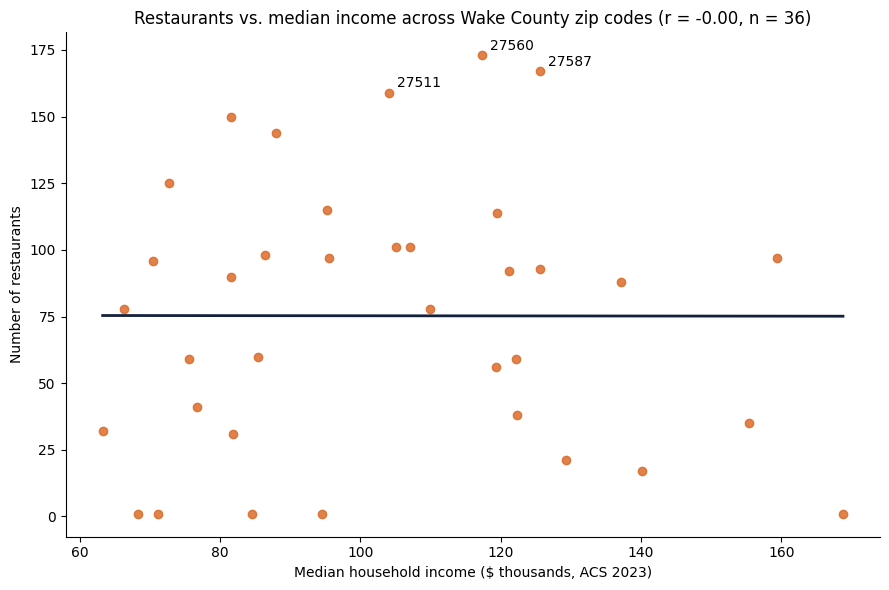

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(analysis["median_income"] / 1000, analysis["n_restaurants"], color="#D9641E", alpha=0.8)

slope, intercept = np.polyfit(analysis["median_income"] / 1000, analysis["n_restaurants"], 1)
xs = np.linspace(analysis["median_income"].min() / 1000, analysis["median_income"].max() / 1000, 100)
ax.plot(xs, slope * xs + intercept, color="#14213D", linewidth=2)

for _, row in analysis.nlargest(3, "n_restaurants").iterrows():
    ax.annotate(row["zip"], (row["median_income"] / 1000, row["n_restaurants"]),
                xytext=(6, 4), textcoords="offset points", fontsize=10)

ax.set_xlabel("Median household income ($ thousands, ACS 2023)")
ax.set_ylabel("Number of restaurants")
ax.set_title(f"Restaurants vs. median income across Wake County zip codes (r = {r:.2f}, n = {len(analysis)})")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "restaurants_vs_income.png", dpi=150)
plt.show()


### 5d. Top zips

In [31]:
cols = ["zip", "n_restaurants", "median_income"]
print("Most restaurants:")
print(analysis.sort_values("n_restaurants", ascending=False)[cols].head(5).to_string(index=False))
print("\nHighest income:")
print(analysis.sort_values("median_income", ascending=False)[cols].head(5).to_string(index=False))


Most restaurants:
  zip  n_restaurants  median_income
27560            173       117340.0
27587            167       125607.0
27511            159       104072.0
27609            150        81538.0
27603            144        87939.0

Highest income:
  zip  n_restaurants  median_income
27562              1       168804.0
27519             97       159414.0
27608             35       155433.0
27539             17       140121.0
27502             88       137088.0


**Short answer:** Income does not seem to affect how many restaurants a zip code has.

**The numbers:** Across 36 Wake County zip codes, the correlation between restaurant count and median income was r = 0.00 (p = 0.99). That means no relationship. Counting all food places instead of just restaurants gave almost the same result (r = 0.09).

**Examples:** Morrisville (27560) has the most restaurants (173) and a median income of about $117k. But the richest zip, New Hill (27562, about $169k), has only 1 restaurant. Some lower income Raleigh zips like 27609 and 27603 have around 150 restaurants each.

**What I think is going on:** Restaurants probably follow where lots of people live and shop, not how much money they make. I did not test this, because I only counted restaurants and did not adjust for population or size of each zip code.

**What I am not sure about:** 36 zip codes is a small sample, so a weak relationship could still exist. 8 zip codes were left out because the Census had no income data for them.

**Data note:** On my final run (Nov 19, 2026), the Wake County API was down, so the notebook used the data I saved in the repo on Oct 2, 2026 (4,182 facilities).